In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

df = pd.read_json("study_habits_demo.json")
df = pd.json_normalize(df["records"])


In [4]:
df.head()

,Student,StudyHours,ExamScore,StudyMethod
0,1,2,60,Group
1,2,3,65,Solo
2,3,4,67,Group
3,4,5,70,Solo
4,5,6,74,Group


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Student      20 non-null     int64
 1   StudyHours   20 non-null     int64
 2   ExamScore    20 non-null     int64
 3   StudyMethod  20 non-null     str  
dtypes: int64(3), str(1)
memory usage: 862.0 bytes


In [6]:
df.describe()

,Student,StudyHours,ExamScore
count,20.00000,20.000000,20.000000
mean,10.50000,6.200000,74.800000
std,5.91608,2.764436,9.671445
min,1.00000,2.000000,58.000000
25%,5.75000,4.000000,68.500000
50%,10.50000,6.000000,74.500000
75%,15.25000,8.250000,82.250000
max,20.00000,11.000000,91.000000


In [7]:
df["StudyMethod"].value_counts()

StudyMethod
Group    10
Solo     10
Name: count, dtype: int64

In [8]:
df.groupby("StudyMethod")["ExamScore"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
StudyMethod,,,,
Group,10,75.5,74.5,9.300538
Solo,10,74.1,74.0,10.482260


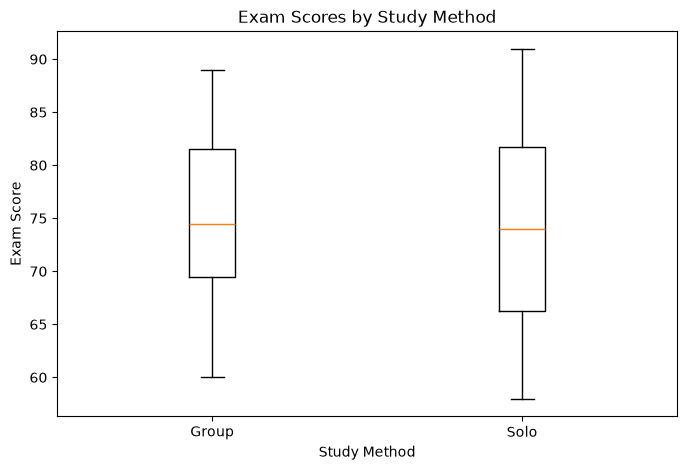

In [10]:
group = df[df["StudyMethod"] == "Group"]["ExamScore"]
solo = df[df["StudyMethod"] == "Solo"]["ExamScore"]

plt.figure(figsize=(8,5))

plt.boxplot(
    [group, solo],
    tick_labels=["Group", "Solo"]
)

plt.xlabel("Study Method")
plt.ylabel("Exam Score")
plt.title("Exam Scores by Study Method")
plt.show()

In [11]:
model_a = ols(
    "ExamScore ~ C(StudyMethod)",
    data=df
).fit()

print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:              ExamScore   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                 -0.050
Method:                 Least Squares   F-statistic:                   0.09981
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.756
Time:                        14:40:56   Log-Likelihood:                -73.194
No. Observations:                  20   AIC:                             150.4
Df Residuals:                      18   BIC:                             152.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 75

In [13]:

print(model_a.pvalues)


Intercept                 3.783151e-15
C(StudyMethod)[T.Solo]    7.556945e-01
dtype: float64


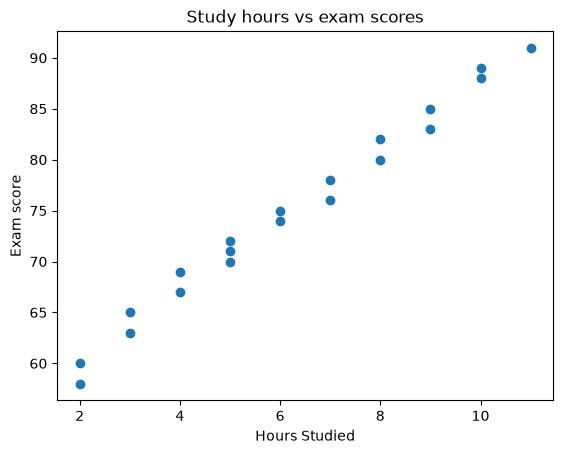

In [14]:
plt.scatter(
    df["StudyHours"],
    df["ExamScore"]
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam score")
plt.title("Study hours vs exam scores")
plt.show()

In [15]:
correlation = df["StudyHours"].corr(
    df["ExamScore"]
)
print("Correlation: ", correlation)

Correlation:  0.9937288209430993


In [16]:
model_b = ols(
    "ExamScore ~ StudyHours",
    data=df
).fit()

print(model_b.summary())

                            OLS Regression Results                            
Dep. Variable:              ExamScore   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     1422.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           1.39e-18
Time:                        14:54:58   Log-Likelihood:                -29.432
No. Observations:                  20   AIC:                             62.86
Df Residuals:                      18   BIC:                             64.85
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     53.2452      0.623     85.421      0.0

In [17]:
print("Intercept:", model_b.params["Intercept"])
print("Slope:", model_b.params["StudyHours"])

Intercept: 53.24517906336089
Slope: 3.4765840220385646


In [18]:
print("Pvalue", model_b.pvalues["StudyHours"])

Pvalue 1.3927404482945597e-18


In [19]:
print("rsquared:", model_b.rsquared)

rsquared: 0.9874969695729624


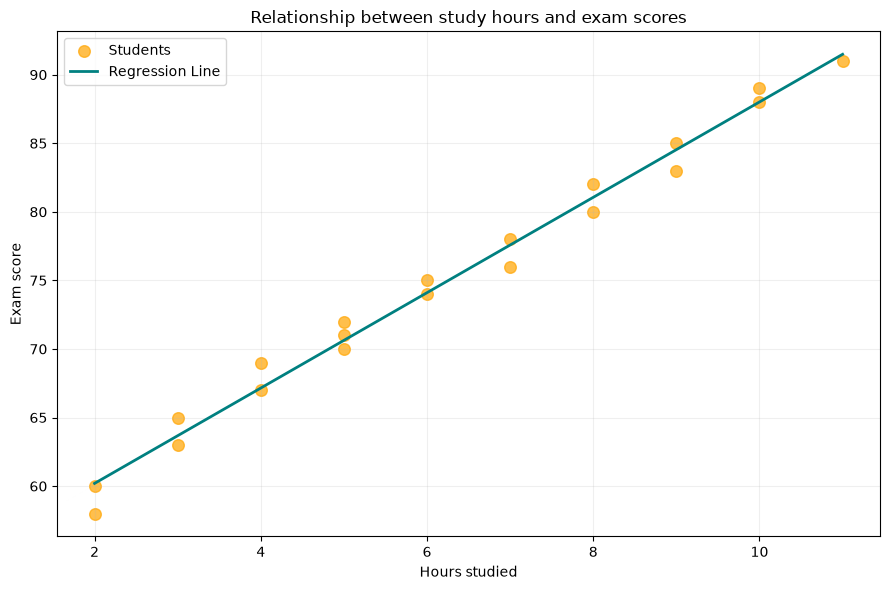

In [20]:
df_sorted = df.sort_values("StudyHours")

#calc predicted scores
predicted = model_b.predict(df_sorted)
plt.figure(figsize=(9,6))

#original
plt.scatter(
    df["StudyHours"],
    df["ExamScore"],
    color="orange",
    alpha=0.7,
    s=70,
    label="Students"
)

#line
plt.plot(
    df_sorted["StudyHours"],
    predicted,
    color="teal",
    linewidth = 2,
    label="Regression Line"
)

plt.xlabel("Hours studied")
plt.ylabel("Exam score")
plt.title("Relationship between study hours and exam scores")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()